# Importing Necessities

In [1]:
import os, random
import numpy as np
from PIL import Image

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF
import torchvision
from torchvision.transforms import InterpolationMode

from pycocotools.coco import COCO
import pycocotools.mask as maskUtils

import matplotlib.pyplot as plt

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [3]:
dataset_dir = 'dataset'

# Importing Dataset

In [4]:
class CrosswalkShadowCocoDataset(Dataset):

    def __init__(self, dataset_dir, image_ids, train=True):

        self.dataset_dir = dataset_dir
        self.ann_file = os.path.join(dataset_dir, "_annotations.coco.json")
        self.coco = COCO(self.ann_file)
        self.image_ids = image_ids
        self.train = train

        cats = self.coco.loadCats(self.coco.getCatIds())


        self.coco_id_to_class = {}
        for cat in cats:
            name = cat["name"].lower()
            if "crosswalk" in name:

                self.coco_id_to_class[cat["id"]] = 1
            elif "shadow" in name:
                self.coco_id_to_class[cat["id"]] = 2

        self.mean = [0.485, 0.456, 0.406]
        self.std  = [0.229, 0.224, 0.225]

        self.target_size = (512, 512)

    def __len__(self):
        return len(self.image_ids)

    def _build_mask(self, img_info):
    
        h, w = img_info["height"], img_info["width"]
        mask = np.zeros((h, w), dtype=np.uint8)

        for coco_cat_id, class_idx in sorted(self.coco_id_to_class.items(),
                                         key=lambda x: x[1]):
            ann_ids = self.coco.getAnnIds(imgIds=[img_info["id"]],
                                      catIds=[coco_cat_id])
            anns = self.coco.loadAnns(ann_ids)

            for ann in anns:
                rle = self.coco.annToRLE(ann)
                binary_mask = maskUtils.decode(rle)

                if binary_mask.ndim == 3:
                    binary_mask = binary_mask[:, :, 0]

                binary_mask = binary_mask.astype(bool)
                mask[binary_mask] = class_idx

        return mask


    def _augment(self, image, mask):

        if random.random() < 0.5:
            image = TF.hflip(image)
            mask = TF.hflip(mask)
        return image, mask

    def __getitem__(self, idx):
        img_id = self.image_ids[idx]
        img_info = self.coco.loadImgs([img_id])[0]
        img_path = os.path.join(self.dataset_dir, img_info["file_name"])

        image = Image.open(img_path).convert("RGB")

        mask_np = self._build_mask(img_info)   
        mask = Image.fromarray(mask_np)       

        if self.train:
            image, mask = self._augment(image, mask)

        image = TF.resize(image, self.target_size,
                          interpolation=InterpolationMode.BILINEAR)
        mask  = TF.resize(mask,  self.target_size,
                          interpolation=InterpolationMode.NEAREST)

        image = TF.to_tensor(image)
        image = TF.normalize(image, self.mean, self.std)

        mask = torch.as_tensor(np.array(mask), dtype=torch.long)

        return image, mask

In [5]:
coco = COCO(os.path.join(dataset_dir, "_annotations.coco.json"))
all_img_ids = list(coco.imgs.keys())
random.shuffle(all_img_ids)

N = len(all_img_ids)
n_train = int(0.8 * N)
n_val   = int(0.1 * N)
n_test  = N - n_train - n_val

train_ids = all_img_ids[:n_train]
val_ids   = all_img_ids[n_train:n_train + n_val]
test_ids  = all_img_ids[n_train + n_val:]

print("Total:", N, "Train:", len(train_ids), "Val:", len(val_ids), "Test:", len(test_ids))

train_dataset = CrosswalkShadowCocoDataset(dataset_dir, train_ids, train=True)
val_dataset   = CrosswalkShadowCocoDataset(dataset_dir, val_ids,   train=False)
test_dataset  = CrosswalkShadowCocoDataset(dataset_dir, test_ids,  train=False)

batch_size = 8

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_dataset,   batch_size=batch_size, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_dataset,  batch_size=batch_size, shuffle=False, num_workers=0)

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
Total: 210 Train: 168 Val: 21 Test: 21
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


Images: torch.Size([8, 3, 512, 512])
Masks: torch.Size([8, 512, 512])
Unique mask values: tensor([0, 1, 2])


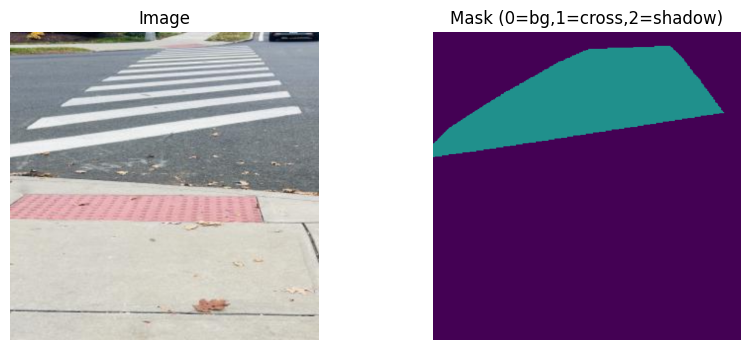

In [6]:
def denormalize(img_tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
    img = img_tensor * std + mean
    return img.clamp(0,1)

def show_image_and_mask(img_tensor, mask_tensor):
    img = denormalize(img_tensor).permute(1,2,0).cpu().numpy()
    mask = mask_tensor.cpu().numpy()

    plt.figure(figsize=(10,4))
    plt.subplot(1,2,1); plt.imshow(img);  plt.title("Image"); plt.axis("off")
    plt.subplot(1,2,2); plt.imshow(mask, vmin=0, vmax=2); plt.title("Mask (0=bg,1=cross,2=shadow)"); plt.axis("off")
    plt.show()
    
images, masks = next(iter(train_loader))
print("Images:", images.shape)
print("Masks:", masks.shape)
print("Unique mask values:", masks.unique())
show_image_and_mask(images[7], masks[7])

# Loading DeepLabv3+ and replacing last layer

In [7]:
model = torchvision.models.segmentation.deeplabv3_resnet50(weights="DEFAULT")

model.classifier[-1] = nn.Conv2d(in_channels=256, out_channels=3, kernel_size=1)

model = model.to(device)

criterion = nn.CrossEntropyLoss()

# IoU metric for segmentation

In [8]:
def compute_mean_iou(preds, targets, num_classes=3):
    ious = []
    preds = preds.cpu()
    targets = targets.cpu()

    for cls in range(num_classes):
        pred_cls = (preds == cls)
        target_cls = (targets == cls)

        intersection = (pred_cls & target_cls).sum().item()
        union = (pred_cls | target_cls).sum().item()

        if union == 0:
            continue  
        ious.append(intersection / union)

    if len(ious) == 0:
        return 0.0
    return sum(ious) / len(ious)


# Baseline Evaluation (Without Any Training as Per Requirement)

In [9]:
def evaluate_baseline(model, loader, split_name=""):
    model.eval()
    total_loss = 0.0
    total_iou  = 0.0
    num_batches = 0

    with torch.no_grad():
        for images, masks in loader:
            images = images.to(device)
            masks  = masks.to(device)

            outputs = model(images)["out"]   
            loss = criterion(outputs, masks)

            preds = outputs.argmax(dim=1)    

            batch_iou = compute_mean_iou(preds, masks, num_classes=3)

            total_loss += loss.item()
            total_iou  += batch_iou
            num_batches += 1

    avg_loss = total_loss / num_batches
    avg_iou  = total_iou / num_batches

    print(f"{split_name} - Avg loss: {avg_loss:.4f}, Mean IoU: {avg_iou:.4f}")
    return avg_loss, avg_iou

train_loss, train_iou = evaluate_baseline(model, train_loader, split_name="Train (baseline, no training)")
val_loss,   val_iou   = evaluate_baseline(model, val_loader,   split_name="Val   (baseline, no training)")

Train (baseline, no training) - Avg loss: 1.1213, Mean IoU: 0.1141
Val   (baseline, no training) - Avg loss: 1.0923, Mean IoU: 0.1320


# Visualizing the 1st sample of each minibatch of size 8 and its prediction

In [10]:
def denormalize(img_tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
    img = img_tensor * std + mean
    return img.clamp(0,1)

In [11]:
def visualize_batch_predictions(model, loader, num_batches=3):
    model.eval()
    with torch.no_grad():
        for batch_idx, (images, masks) in enumerate(loader):
            if batch_idx >= num_batches:
                break

            images = images.to(device)

            outputs = model(images)["out"]
            preds = outputs.argmax(dim=1)  

            img = images[0].cpu()
            gt_mask = masks[0].cpu()        
            pred_mask = preds[0].cpu()

            img_vis = denormalize(img).permute(1,2,0).numpy()

            plt.figure(figsize=(12,4))
            plt.subplot(1,3,1); plt.imshow(img_vis);     plt.title(f"Batch {batch_idx} - Image"); plt.axis("off")
            plt.subplot(1,3,2); plt.imshow(gt_mask, vmin=0, vmax=2);   plt.title("GT Mask"); plt.axis("off")
            plt.subplot(1,3,3); plt.imshow(pred_mask, vmin=0, vmax=2); plt.title("Pred Mask (baseline)"); plt.axis("off")
            plt.show()

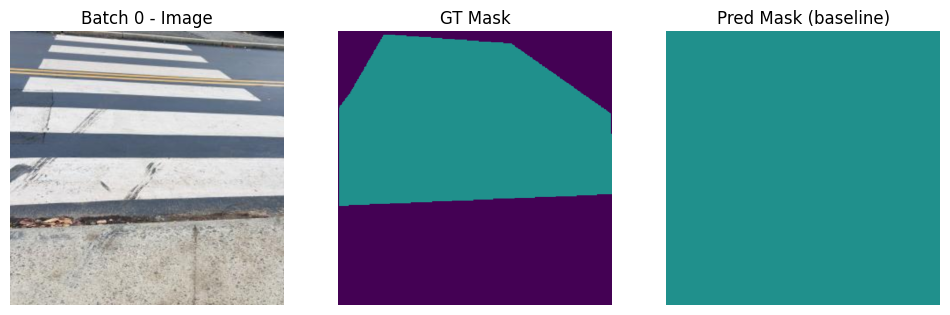

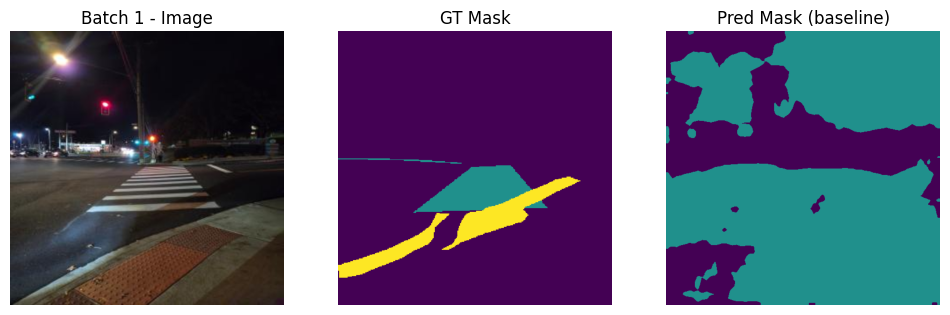

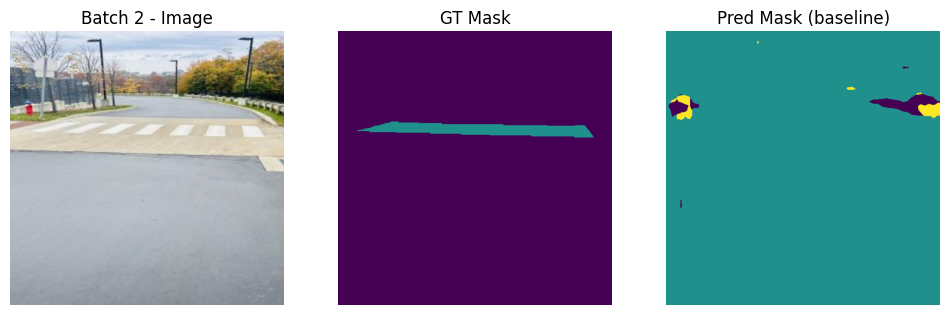

In [12]:
visualize_batch_predictions(model, train_loader, num_batches=3)